# 01. Análise Exploratória de Dados (EDA) — Risco de Queimadas no Brasil (Mato Grosso)

## 1. Introdução e Contexto
O objetivo deste projeto é prever a probabilidade de ocorrência de focos de calor em células regulares de grade (~0,5° ≈ 56 km) nos próximos 7 dias no estado do **Mato Grosso**.

Mato Grosso é historicamente uma das unidades federativas com maior incidência de queimadas e incêndios florestais no Brasil, abrangendo áreas dos biomas **Cerrado**, **Amazônia** e **Pantanal**.

### Fontes de Dados Utilizadas:
1. **Programa Queimadas (INPE)**: Focos de calor detectados pelo satélite de referência **AQUA_M-T** (sensor MODIS, passagem vespertina) no período de 2016 a 2025 (~10 anos de histórico consolidado).
2. **NASA POWER**: Variáveis meteorológicas diárias em grade (temperatura máxima/mínima, umidade relativa a 2m, precipitação acumulada e velocidade do vento a 10m).

Neste notebook, exploramos os padrões temporais, espaciais e climáticos que governam a dinâmica do fogo na região piloto.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configurações visuais
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

PROJECT_ROOT = Path("..")


## 2. Carregamento dos Dados Processados
Carregamos o dataset tabular gerado pelo pipeline de processamento em `data/processed/dataset.parquet`.


In [2]:
dataset_path = PROJECT_ROOT / "data" / "processed" / "dataset.parquet"
df = pd.read_parquet(dataset_path)
df['date'] = pd.to_datetime(df['date'])

print(f"Dimensões do dataset: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print(f"Período temporal coberto: {df['date'].min().date()} até {df['date'].max().date()}")
print(f"Total de células na grade espacial: {df['grid_id'].nunique()}")
df.head()


Dimensões do dataset: 1,848,418 linhas × 13 colunas
Período temporal coberto: 2016-01-01 até 2025-12-31
Total de células na grade espacial: 506


,grid_id,date,fire_count,target,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M,grid_row,grid_col,lat_center,lon_center
0,000_000,2016-01-01,0,0,36.86,25.02,57.75,0.25,2.54,0,0,-17.85,-61.45
1,000_000,2016-01-02,0,0,35.84,25.53,57.94,0.02,2.51,0,0,-17.85,-61.45
2,000_000,2016-01-03,0,0,36.02,24.51,57.55,2.08,2.64,0,0,-17.85,-61.45
3,000_000,2016-01-04,0,0,37.11,24.72,61.62,4.19,2.70,0,0,-17.85,-61.45
4,000_000,2016-01-05,0,0,36.61,25.02,63.21,0.88,2.33,0,0,-17.85,-61.45


## 3. Distribuição e Balanceamento do Alvo Binário (`target`)
O alvo é definido como: **houve pelo menos 1 foco de calor na célula nos próximos 7 dias (D+1 a D+7)?**


Distribuição da Variável Alvo:
        Ocorrências  Porcentagem (%)
target                              
0           1499012             81.1
1            349406             18.9


C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_22280\3871557717.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_pct.index, y=target_pct.values, palette=['#2ecc71', '#e74c3c'], ax=ax)


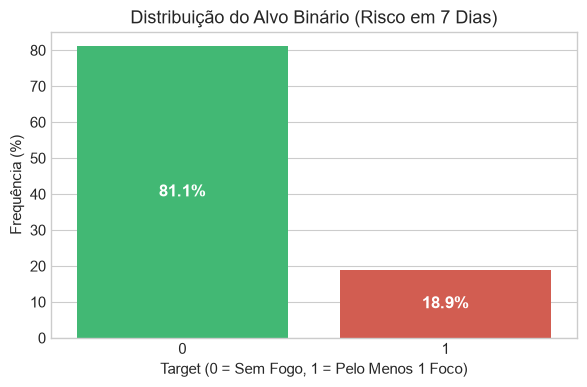

In [3]:
target_counts = df['target'].value_counts()
target_pct = df['target'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Ocorrências': target_counts,
    'Porcentagem (%)': target_pct.round(2)
})
print("Distribuição da Variável Alvo:")
print(summary_target)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=target_pct.index, y=target_pct.values, palette=['#2ecc71', '#e74c3c'], ax=ax)
ax.set_title("Distribuição do Alvo Binário (Risco em 7 Dias)")
ax.set_xlabel("Target (0 = Sem Fogo, 1 = Pelo Menos 1 Foco)")
ax.set_ylabel("Frequência (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()


> **Observação técnica:** A classe positiva representa aproximadamente 19% dos registros. Esse desbalanceamento moderado justifica o uso de métricas como **PR-AUC** (Precision-Recall AUC) como métrica primária em vez de acurácia ou ROC-AUC isolada, além de ponderação por `scale_pos_weight`.


## 4. Dinâmica Temporal e Sazonalidade das Queimadas
Análise de como as ocorrências de focos variam ao longo do ano e através dos anos de 2016 a 2025.


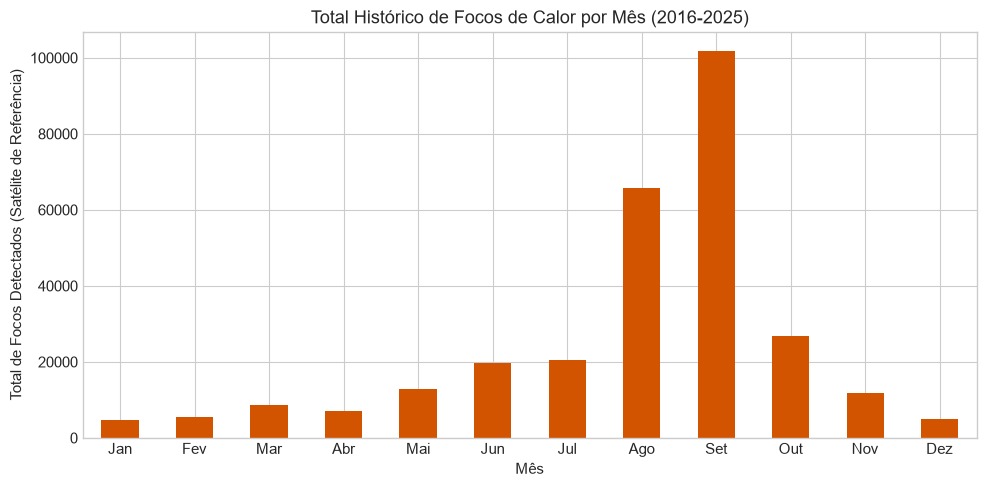

In [4]:
# Focos agregados por mês
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year

monthly_fires = df.groupby('month')['fire_count'].sum()

fig, ax = plt.subplots(figsize=(10, 5))
monthly_fires.plot(kind='bar', color='#d35400', ax=ax)
ax.set_title("Total Histórico de Focos de Calor por Mês (2016-2025)")
ax.set_xlabel("Mês")
ax.set_ylabel("Total de Focos Detectados (Satélite de Referência)")
ax.set_xticklabels(['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'], rotation=0)
plt.tight_layout()
plt.show()


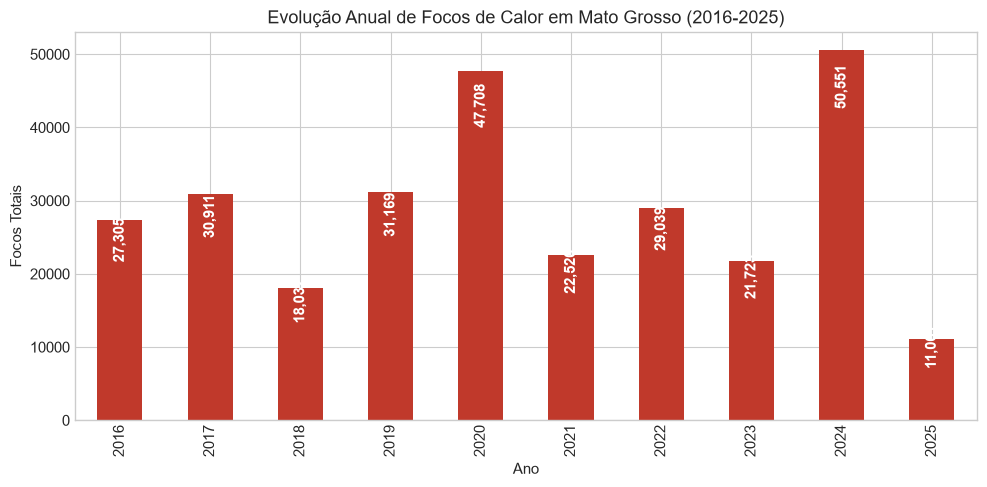

In [5]:
# Total anual de focos de calor
annual_fires = df.groupby('year')['fire_count'].sum()

fig, ax = plt.subplots(figsize=(10, 5))
annual_fires.plot(kind='bar', color='#c0392b', ax=ax)
ax.set_title("Evolução Anual de Focos de Calor em Mato Grosso (2016-2025)")
ax.set_xlabel("Ano")
ax.set_ylabel("Focos Totais")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                ha='center', va='center', color='white', fontweight='bold', rotation=90)
plt.tight_layout()
plt.show()


## 5. Relação com Variáveis Climáticas (NASA POWER)
Investigamos como a temperatura máxima (`T2M_MAX`), umidade relativa (`RH2M`) e precipitação acumulada (`PRECTOTCORR`) se comportam em dias com fogo vs. dias sem fogo.


Médias Climáticas (Target 0 vs. Target 1):
target           0      1
T2M_MAX      31.98  33.52
T2M_MIN      21.88  21.93
RH2M         69.76  61.53
PRECTOTCORR   3.80   2.43
WS10M         1.60   1.59


C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_22280\4082352155.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='T2M_MAX', data=df.sample(50000, random_state=42), ax=axes[0], palette=['#3498db', '#e74c3c'])
C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_22280\4082352155.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Sem Fogo (0)', 'Com Fogo (1)'])
C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_22280\4082352155.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='RH2M', data=df.sample(50000,

C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_22280\4082352155.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='PRECTOTCORR', data=df.sample(50000, random_state=42), ax=axes[2], palette=['#3498db', '#e74c3c'])
C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_22280\4082352155.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(['Sem Fogo (0)', 'Com Fogo (1)'])


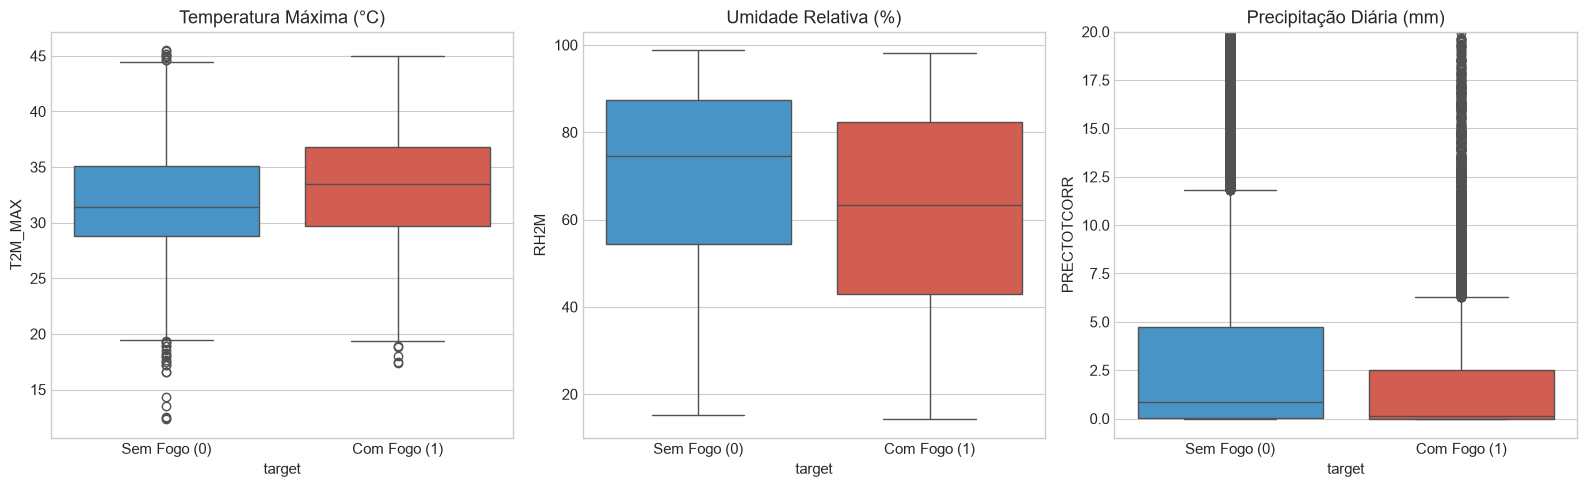

In [6]:
# Comparação de médias climáticas por classe de risco
climate_cols = ['T2M_MAX', 'T2M_MIN', 'RH2M', 'PRECTOTCORR', 'WS10M']
climate_comparison = df.groupby('target')[climate_cols].mean().round(2)
print("Médias Climáticas (Target 0 vs. Target 1):")
print(climate_comparison.T)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x='target', y='T2M_MAX', data=df.sample(50000, random_state=42), ax=axes[0], palette=['#3498db', '#e74c3c'])
axes[0].set_title("Temperatura Máxima (°C)")
axes[0].set_xticklabels(['Sem Fogo (0)', 'Com Fogo (1)'])

sns.boxplot(x='target', y='RH2M', data=df.sample(50000, random_state=42), ax=axes[1], palette=['#3498db', '#e74c3c'])
axes[1].set_title("Umidade Relativa (%)")
axes[1].set_xticklabels(['Sem Fogo (0)', 'Com Fogo (1)'])

sns.boxplot(x='target', y='PRECTOTCORR', data=df.sample(50000, random_state=42), ax=axes[2], palette=['#3498db', '#e74c3c'])
axes[2].set_title("Precipitação Diária (mm)")
axes[2].set_ylim(-1, 20)
axes[2].set_xticklabels(['Sem Fogo (0)', 'Com Fogo (1)'])

plt.tight_layout()
plt.show()


## 6. Distribuição Espacial dos Focos
Avaliando a frequência de focos na grade de Mato Grosso por coordenadas de latitude e longitude.


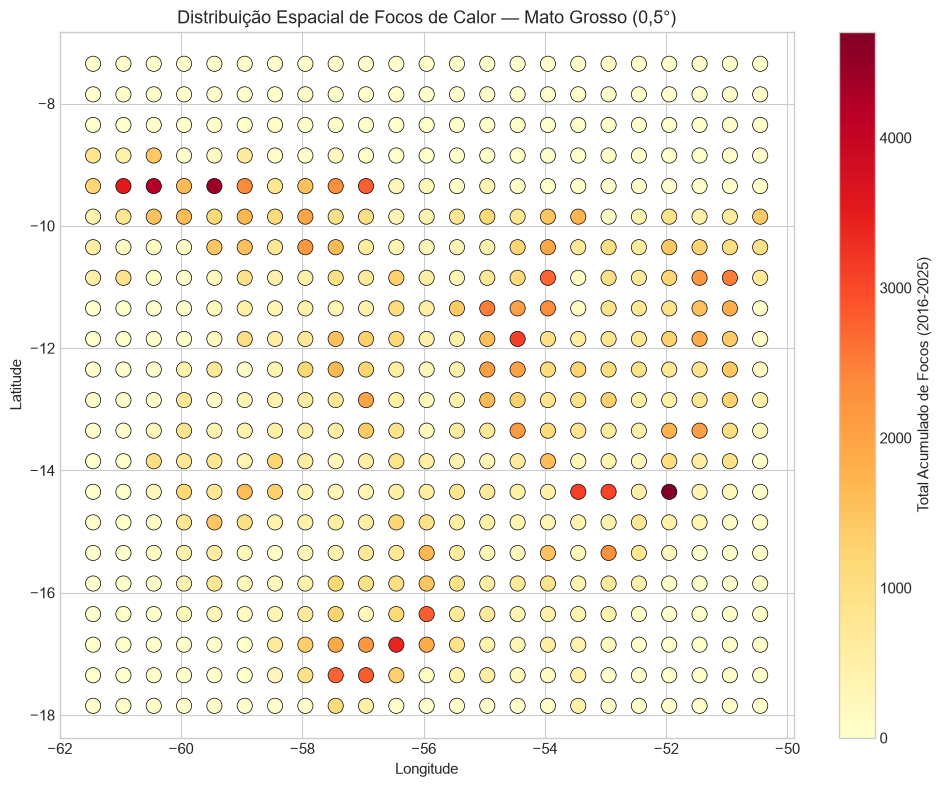

In [7]:
spatial_density = df.groupby(['lat_center', 'lon_center'])['fire_count'].sum().reset_index()

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(spatial_density['lon_center'], spatial_density['lat_center'], 
                c=spatial_density['fire_count'], cmap='YlOrRd', s=120, edgecolors='black', linewidth=0.5)
plt.colorbar(sc, label="Total Acumulado de Focos (2016-2025)")
ax.set_title("Distribuição Espacial de Focos de Calor — Mato Grosso (0,5°)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()


## 7. Conclusões e Decisões para Modelagem
1. **Sazonalidade Marcante**: A temporada de queimadas em Mato Grosso concentra-se quase que inteiramente entre julho e outubro (com pico absoluto em agosto/setembro), coincidindo com o período seco do Centro-Oeste brasileiro. Variáveis cíclicas (`month_sin`, `month_cos`, `doy_sin`, `doy_cos`) são fundamentais.
2. **Sinal Climático Expressivo**: Dias com subsequente ocorrência de fogo apresentam umidade relativa significativamente mais baixa (~50-55% vs >70%) e temperaturas máximas mais elevadas (>34°C).
3. **Persistência Espacial e Temporal**: O fogo tem forte autocorrelação espacial (células vizinhas) e temporal (janelas móveis de 7, 14 e 30 dias passadas).
4. **Alvo Desbalanceado (~19% positivos)**: Treinamento com `scale_pos_weight` ou `class_weight='balanced'` é essencial, assim como avaliação por PR-AUC e curvas de calibração.
5. **Divisão de Validação**: Divisão temporal estrita (treino <= 2023, teste 2024-2025) e validação cruzada espacial em blocos (`GroupKFold` por célula) evitam vazamento e testam generalização em anos de secas extremas (como 2024).
